In [ ]:

# ⚡ Electrical Fault Detection Dashboard
# Load saved models and create the interactive frontend

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Find the assignment folders
PROJECT = Path.cwd().parent
DATA = PROJECT / "data" / "detect_dataset.csv"
RESULTS = PROJECT / "results"
RESULTS.mkdir(exist_ok=True)

PARAMS = RESULTS / "logistic_set_q_params.npz"
SVM_MODEL = RESULTS / "best_rbf_svm.joblib"

# Load saved files
df = pd.read_csv(DATA)
saved = np.load(PARAMS)

theta_q = saved["theta_q"]
q_mean = saved["q_mean"]
q_std = saved["q_std"]
rbf_svm = joblib.load(SVM_MODEL)

features = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]

# Use realistic starting values from the dataset
defaults = df[features].median()

# Create six sensor input boxes
inputs = {}
for feature in features:
    inputs[feature] = widgets.FloatText(
        value=float(defaults[feature]),
        description=feature,
        layout=widgets.Layout(width="220px"),
        style={"description_width": "55px"}
    )

# Dashboard title and styling
display(HTML("""
<div style="
background:linear-gradient(120deg,#102746,#164e80);
padding:25px;border-radius:15px;color:white;
font-family:Arial;text-align:center;margin-bottom:15px;">
<h1 style="color:white;margin:0;">⚡ Electrical Fault Detection</h1>
<p style="color:#dbeafe;margin:10px 0 0;">
AI-Based Three-Phase Electrical Monitoring System
</p>
</div>
"""))

display(HTML("""
<h3 style="color:#2471a3;">Sensor Readings</h3>
<p>Enter the six electrical measurements and click Predict Fault.</p>
"""))

input_grid = widgets.GridBox(
    list(inputs.values()),
    layout=widgets.Layout(
        grid_template_columns="repeat(3, 1fr)",
        grid_gap="12px",
        width="100%"
    )
)

predict_button = widgets.Button(
    description="⚡ Predict Fault",
    button_style="primary",
    layout=widgets.Layout(width="220px", height="45px")
)

output = widgets.Output()

display(input_grid)
display(predict_button)
display(output)


# Predict using both saved models
def on_predict_clicked(button):
    with output:
        clear_output(wait=True)

        readings = np.array(
            [[inputs[f].value for f in features]],
            dtype=float
        )

        # Set Q Logistic Regression uses original and squared features
        q_features = np.concatenate(
            [readings, readings ** 2], axis=1
        )
        q_scaled = (q_features - q_mean) / q_std
        q_input = np.column_stack(
            [np.ones(len(q_scaled)), q_scaled]
        )

        score = np.clip(q_input @ theta_q, -500, 500)
        lr_probability = float(
            (1 / (1 + np.exp(-score)))[0]
        )
        lr_prediction = int(lr_probability >= 0.5)

        # Scale SVM inputs using the original training split
        X = df[features].to_numpy(dtype=float)
        rng = np.random.default_rng(42)
        indices = rng.permutation(len(X))
        train_indices = indices[:int(0.60 * len(X))]
        X_train = X[train_indices]

        svm_mean = X_train.mean(axis=0)
        svm_std = X_train.std(axis=0)
        svm_std[svm_std == 0] = 1

        svm_scaled = (readings - svm_mean) / svm_std
        svm_prediction = int(rbf_svm.predict(svm_scaled)[0])

        # Display the results side by side
        lr_color = "#b91c1c" if lr_prediction else "#15803d"
        svm_color = "#b91c1c" if svm_prediction else "#15803d"

        lr_text = (
            "⚠️ ELECTRICAL FAULT DETECTED"
            if lr_prediction else "✅ NO ELECTRICAL FAULT DETECTED"
        )
        svm_text = (
            "⚠️ ELECTRICAL FAULT DETECTED"
            if svm_prediction else "✅ NO ELECTRICAL FAULT DETECTED"
        )

        display(HTML(f"""
        <div style="display:flex;gap:15px;font-family:Arial;">
          <div style="flex:1;background:#102746;color:white;
          padding:20px;border-radius:12px;text-align:center;">
            <h3 style="color:white;">Logistic Regression</h3>
            <p style="color:{lr_color};font-weight:bold;">
              {lr_text}
            </p>
            <p>Model fault score: {lr_probability*100:.2f}%</p>
          </div>
          <div style="flex:1;background:#102746;color:white;
          padding:20px;border-radius:12px;text-align:center;">
            <h3 style="color:white;">RBF SVM</h3>
            <p style="color:{svm_color};font-weight:bold;">
              {svm_text}
            </p>
            <p>Predicted class: {svm_prediction}</p>
          </div>
        </div>
        <p style="color:gray;font-size:12px;">
        Predictions are model outputs, not a substitute for electrical safety checks.
        </p>
        """))

        # Save prediction history
        record = pd.DataFrame([{
            **{f: inputs[f].value for f in features},
            "Logistic_Regression": lr_prediction,
            "LR_fault_score_percent": lr_probability * 100,
            "RBF_SVM": svm_prediction
        }])

        history = RESULTS / "frontend_predictions.csv"
        record.to_csv(
            history,
            mode="a" if history.exists() else "w",
            header=not history.exists(),
            index=False
        )

        print("Prediction saved to:", history)


predict_button.on_click(on_predict_clicked)


GridBox(children=(FloatText(value=-3.239788336, description='Ia', layout=Layout(width='220px'), style=Descript…

Button(button_style='primary', description='⚡ Predict Fault', layout=Layout(height='45px', width='220px'), sty…

Output()

Screenshot saved: e:\dowload\aml assgnment 2\results\frontend_screenshot.png


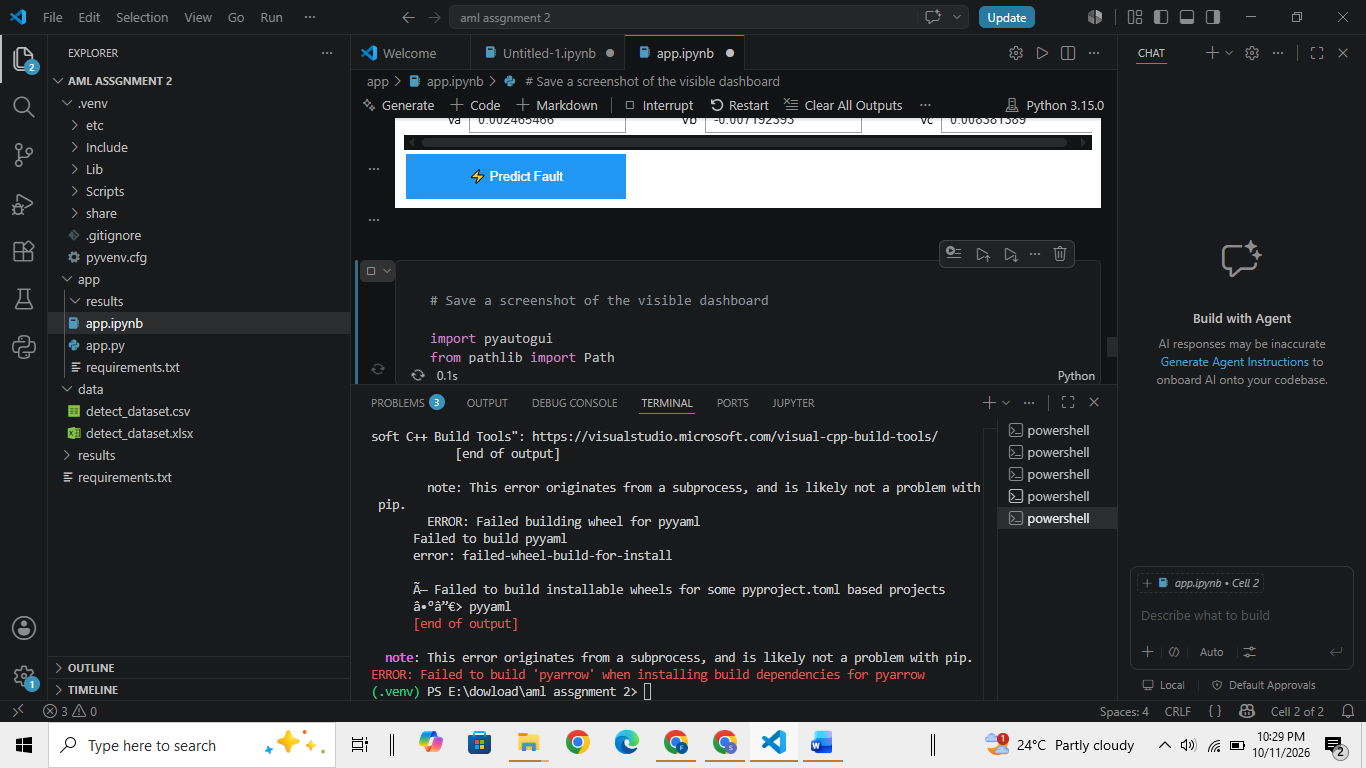

In [2]:

# Save a screenshot of the visible dashboard

import pyautogui
from pathlib import Path
from IPython.display import display, Image

results_folder = Path.cwd().parent / "results"
results_folder.mkdir(exist_ok=True)

screenshot_path = results_folder / "frontend_screenshot.png"

pyautogui.screenshot().save(screenshot_path)

print("Screenshot saved:", screenshot_path)
display(Image(filename=str(screenshot_path)))


In [8]:

# Save dashboard output as a PNG image

from pathlib import Path
from IPython.display import display, HTML
import matplotlib.pyplot as plt

results_folder = Path.cwd().parent / "results"
results_folder.mkdir(exist_ok=True)

screenshot_path = results_folder / "frontend_screenshot.png"

# Create a clean dashboard image
fig = plt.figure(figsize=(14, 7), facecolor="#081426")
fig.text(
    0.5, 0.90, "ELECTRICAL FAULT DETECTION SYSTEM",
    ha="center", color="white", fontsize=21, weight="bold"
)
fig.text(
    0.5, 0.82, "AI-Based Three-Phase Electrical Monitoring",
    ha="center", color="#93c5fd", fontsize=12
)

# Capture current input values
sensor_text = "\n".join(
    f"{name}: {widget.value:.4f}"
    for name, widget in inputs.items()
)

fig.text(
    0.08, 0.67, "SENSOR READINGS",
    color="#60a5fa", fontsize=14, weight="bold"
)
fig.text(
    0.08, 0.60, sensor_text,
    color="white", fontsize=12, linespacing=1.7, va="top"
)

# Add the latest predictions if they exist
fig.text(
    0.58, 0.67, "PREDICTION MODELS",
    color="#60a5fa", fontsize=14, weight="bold"
)

if "lr_prediction" in globals() and "svm_prediction" in globals():
    lr_text = "FAULT DETECTED" if lr_prediction else "NO FAULT DETECTED"
    svm_text = "FAULT DETECTED" if svm_prediction else "NO FAULT DETECTED"

    fig.text(
        0.58, 0.57, f"Logistic Regression\n{lr_text}\n"
        f"Fault score: {lr_probability * 100:.2f}%",
        color="#f87171" if lr_prediction else "#4ade80",
        fontsize=13, linespacing=1.8, va="top"
    )
    fig.text(
        0.58, 0.35, f"RBF SVM\n{svm_text}",
        color="#f87171" if svm_prediction else "#4ade80",
        fontsize=13, linespacing=1.8, va="top"
    )
else:
    fig.text(
        0.58, 0.55, "Click Predict Fault first.",
        color="white", fontsize=12
    )

fig.text(
    0.5, 0.07, "Applied Machine Learning — Assignment 2",
    ha="center", color="#94a3b8", fontsize=10
)

plt.savefig(
    screenshot_path, dpi=180,
    bbox_inches="tight", facecolor=fig.get_facecolor()
)
plt.close(fig)

print("PNG saved to:", screenshot_path)
display(HTML(f"<p>Saved: {screenshot_path.name}</p>"))


PNG saved to: e:\dowload\aml assgnment 2\results\frontend_screenshot.png
